In [1]:
import numpy as np
import csv
import pandas as pd
from scipy.signal import find_peaks
#import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.patches as mpatches
import scipy as sp
import os
from pathlib import Path
#from frechetdist import frdist
from scipy.spatial.distance import euclidean
#from fastdtw import fastdtw

In [2]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

In [42]:
#UMAP stochastic
embedding_prot_erl_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_4-9_1_1.csv',header=None)
embedding_prot_erl_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_4-9_2_1.csv',header=None)
embedding_prot_erl_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_4-9_3_1.csv',header=None)

#prot stochastic
all_prot_erl_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_4-9_1_1.csv',header=None)
all_prot_erl_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_4-9_2_1.csv',header=None)
all_prot_erl_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_4-9_3_1.csv',header=None)

In [39]:
#UMAP stochastic
embedding_prot_dmso_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_4-9_1_1.csv',header=None)
embedding_prot_dmso_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_4-9_2_1.csv',header=None)
embedding_prot_dmso_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_4-9_3_1.csv',header=None)

#prot stochastic
all_prot_dmso_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_4-9_1_1.csv',header=None)
all_prot_dmso_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_4-9_2_1.csv',header=None)
all_prot_dmso_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_4-9_3_1.csv',header=None)

In [24]:
#UMAP stochastic

embedding_erl_long_1_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_long_1_1.csv',header=None)
embedding_erl_long_2_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_long_2_1.csv',header=None)
embedding_erl_long_3_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_long_3_1.csv',header=None)
embedding_dmso_long_1_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_long_1_1.csv',header=None)
embedding_dmso_long_2_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_long_2_1.csv',header=None)
embedding_dmso_long_3_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_long_3_1.csv',header=None)

#prot stochastic

all_prot_erl_long_1_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_long_1_1.csv',header=None)
all_prot_erl_long_2_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_long_2_1.csv',header=None)
all_prot_erl_long_3_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_long_3_1.csv',header=None)
all_prot_dmso_long_1_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_long_1_1.csv',header=None)
all_prot_dmso_long_2_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_long_2_1.csv',header=None)
all_prot_dmso_long_3_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_long_3_1.csv',header=None)

In [4]:
#times

all_time_stoch = pd.read_csv(str(SAVEDIR) + '\\all_time_erl_4-9_1_1.csv',header=None)
all_time_at_stoch = pd.read_csv(str(SAVEDIR) + '\\all_time_at_erl_4-9_1_1.csv',header=None)

In [5]:
embedding_tmp = np.loadtxt(str(SAVEDIR) + '\\embedding_all_ode.csv', delimiter=',')
embedding_index = np.loadtxt(str(SAVEDIR) + '\\embedding_all_ode_index.csv', delimiter=',')

In [7]:
window_size = len(all_prot_erl_long_1_1.columns)/18
cyce=int((window_size*11+window_size/2)-1)
cdc20=int((window_size*17+window_size/2)-1)

In [8]:
window_size

40.0

In [9]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF[cyce], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF[cdc20], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp = np.concatenate(tmp, axis=0)
            tmp_time.insert(1, 'G1', tmp)
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [10]:
def splitIMT(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF[cyce], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF[cdc20], prominence = 40/200, distance = 10)
    
    mit_win = []
    time_win = pd.DataFrame()
    umap_win = []
    count = 0
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[2]):int(ordered[4]),:]
            tmp_arr = tmp_prot.to_numpy()
            tmp_umap = embedDF.iloc[int(ordered[2]):int(ordered[4]),:]
            tmp_umap_arr = tmp_umap.to_numpy()
            tmp_time = timeDF.iloc[int(ordered[2]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp = np.concatenate(tmp, axis=0)
            tmp_time.insert(1, 'G1', tmp)
            
            mit_win = [mit_win, tmp_arr]
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            if len(umap_win)==0:
                umap_win = [tmp_umap_arr]
            else:
                umap_win.append(tmp_umap_arr)
            count += 1
    return tmp_arr, time_win, umap_win, count

In [11]:
peaks_E, _ = find_peaks(all_prot_erl_7_7_1_1[cyce], prominence = 40/200, distance = 10)
peaks_cdc, _ = find_peaks(all_prot_erl_7_7_1_1[cdc20], prominence = 40/200, distance = 10)

NameError: name 'all_prot_erl_7_7_1_1' is not defined

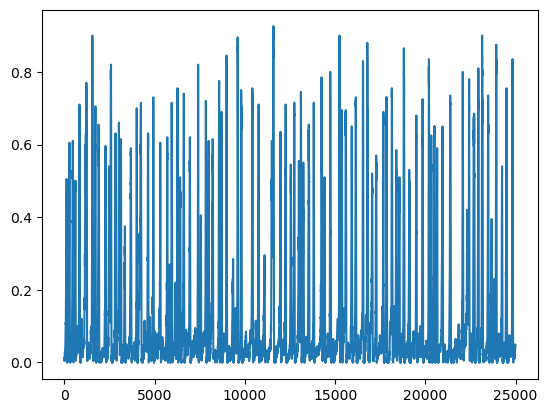

In [56]:
plt.plot(all_prot_erl_7_7_1_1[cyce])

In [22]:
mit_win_erl_1_1, time_win_erl_1_1, umap_win_erl_1_1 = restructProt(all_prot_erl_7_7_1_1, embedding_prot_erl_7_7_1_1, all_time_at_stoch)
mit_win_erl_2_1, time_win_erl_2_1, umap_win_erl_2_1 = restructProt(all_prot_erl_7_7_2_1, embedding_prot_erl_7_7_2_1, all_time_at_stoch)
mit_win_erl_3_1, time_win_erl_3_1, umap_win_erl_3_1 = restructProt(all_prot_erl_7_7_3_1, embedding_prot_erl_7_7_3_1, all_time_at_stoch)

In [25]:
mit_all_erl_1_1, test1, umap_all_erl_1_1, count = splitIMT(all_prot_erl_7_7_1_1, embedding_prot_erl_7_7_1_1, all_time_at_stoch)
mit_all_erl_2_1, test2, umap_all_erl_2_1, count = splitIMT(all_prot_erl_7_7_2_1, embedding_prot_erl_7_7_2_1, all_time_at_stoch)
mit_all_erl_3_1, test3, umap_all_erl_3_1, count = splitIMT(all_prot_erl_7_7_3_1, embedding_prot_erl_7_7_3_1, all_time_at_stoch)

NameError: name 'all_prot_erl_7_7_1_1' is not defined

In [19]:
mit_win_dmso_1_1, time_win_dmso_1_1, umap_win_dmso_1_1 = restructProt(all_prot_dmso_7_7_1_1, embedding_prot_dmso_7_7_1_1, all_time_at_stoch)
mit_win_dmso_2_1, time_win_dmso_2_1, umap_win_dmso_2_1 = restructProt(all_prot_dmso_7_7_2_1, embedding_prot_dmso_7_7_2_1, all_time_at_stoch)
mit_win_dmso_3_1, time_win_dmso_3_1, umap_win_dmso_3_1 = restructProt(all_prot_dmso_7_7_3_1, embedding_prot_dmso_7_7_3_1, all_time_at_stoch)

NameError: name 'all_prot_dmso_7_7_1_1' is not defined

In [26]:
mit_all_erl_1_1, test1, umap_all_erl_1_1, count = splitIMT(all_prot_erl_long_1_1, embedding_erl_long_1_1, all_time_at_stoch)
mit_all_erl_2_1, test2, umap_all_erl_2_1, count = splitIMT(all_prot_erl_long_2_1, embedding_erl_long_2_1, all_time_at_stoch)
mit_all_erl_3_1, test3, umap_all_erl_3_1, count = splitIMT(all_prot_erl_long_3_1, embedding_erl_long_3_1, all_time_at_stoch)

In [21]:
def plot_by_class(UMAP_vals):
    fig = plt.figure()
    erl_slow = 0
    erl_fast = 0
    dmso = 0

    
    xmin, xmax = -5, 15
    ymin, ymax = -5, 15
    ind = np.where(embedding_index == 1) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])

    for ii in range(1001,2001):
        ind = np.where(embedding_index == ii) 
        x=np.ndarray.tolist(embedding_tmp[ind,0])
        y=np.ndarray.tolist(embedding_tmp[ind,1])
        plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightblue')
    ind = np.where(embedding_index == 1001) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])    
    dmso_plot = mpatches.Patch(color='lightblue')
    

    for ii in range(0,113):
        ind = np.where(embedding_index == ii) 
        x=np.ndarray.tolist(embedding_tmp[ind,0])
        y=np.ndarray.tolist(embedding_tmp[ind,1])
        plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen')
    ind = np.where(embedding_index == 1) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])
    erl_slow_plot = mpatches.Patch(color='lightgreen')
    
    for ii in range(114,1001):
        ind = np.where(embedding_index == ii) 
        x=np.ndarray.tolist(embedding_tmp[ind,0])
        y=np.ndarray.tolist(embedding_tmp[ind,1])
        plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgrey')
    ind = np.where(embedding_index == 113) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])
    erl_fast_plot = mpatches.Patch(color='lightgrey')

    for num in range(len(UMAP_vals)):
        state = [0] * len(UMAP_vals[num])
        for val in range(len(UMAP_vals[num])): 
            if (UMAP_vals[num][val,0]>10) & (UMAP_vals[num][val,1]>10):
                state[val]=2
            elif (7>UMAP_vals[num][val,0]>4) & (7>UMAP_vals[num][val,1]>4):
                state[val]=1

        if any(item==2 for item in state):
            color='darkgreen'
            erl_slow += 1
        elif any(item==1 for item in state):
            color='darkblue'
            dmso += 1
        else:
            color='dimgrey'
            erl_fast += 1

        plt.plot(UMAP_vals[num][:,0], UMAP_vals[num][:,1], c=color, lw=0.3)
        classes = [erl_slow, erl_fast, dmso]
        total = erl_slow + erl_fast + dmso
        perc = [(x/total)*100 for x in classes]
        
        plt.xlim([xmin, xmax])
        plt.ylim([ymin, ymax])
        plt.xticks([-5, 0, 5, 10])
        plt.yticks([-5, 0, 5, 10])
    
        plt.legend([dmso_plot, erl_fast_plot, erl_slow_plot], 
                   (f'+DMSO: {round(perc[2],2)}%', f'+ERL fast: {round(perc[1],2)}%', f'+ERL slow: {round(perc[0],2)}%'), 
                   loc=2, fontsize=8)
        
        '+DMSO, ODE' '+ERL, ODE'
    return classes

[48, 24, 2]

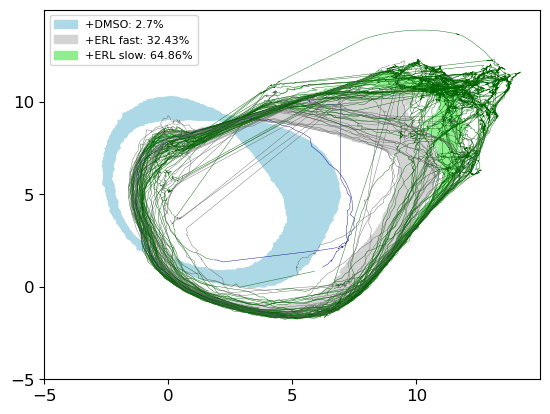

In [386]:
plot_by_class(umap_all_erl_1_1)

[31, 38, 2]

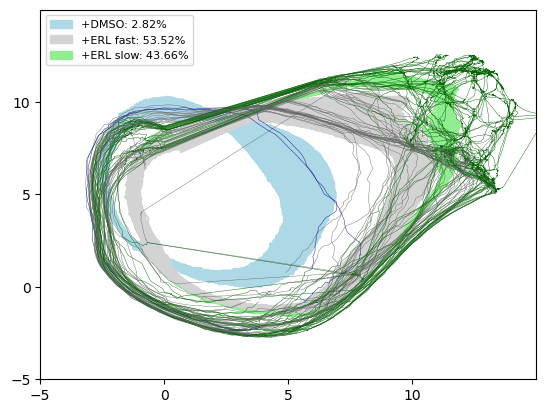

In [27]:
plot_by_class(umap_all_erl_1_1)

[16, 93, 33]

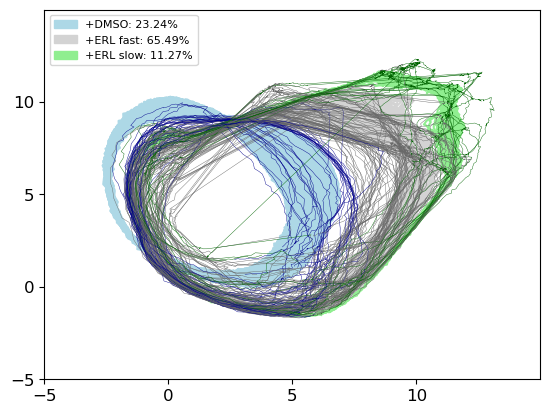

In [387]:
plot_by_class(umap_all_erl_2_1)

[10, 103, 23]

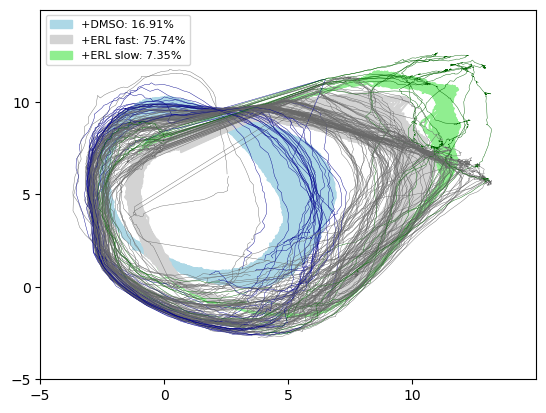

In [28]:
plot_by_class(umap_all_erl_2_1)

[8, 107, 36]

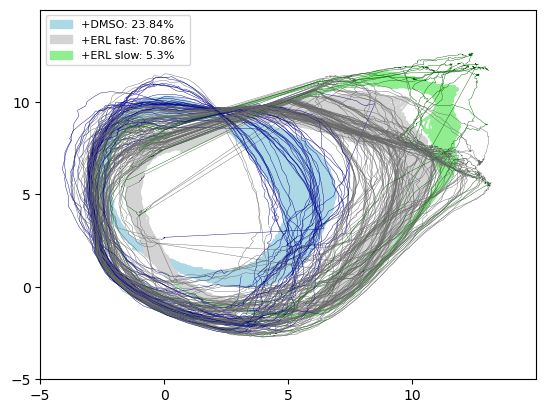

In [29]:
plot_by_class(umap_all_erl_3_1)